# Water Quality Assessment using Implicative Fuzzy Inference Systems
**Project Overview:** This notebook implements a fuzzy logic-based approach to evaluate river water quality based on physical and chemical parameters. It utilizes an **Implicative Inference System** to map environmental data (such as oxygen levels, nitrogen, and phosphorus) to quality categories ranging from "Great" to "Bad".

### Key Features:
* **Data Processing:** Loads and filters river quality datasets (`River_quality_data_2023.csv`) and predefined quality intervals (`Phisical_Chemical_quality_intervals.csv`).
* **Fuzzy Inference:** Implements an `ImplicativeInferenceSystem` using Łukasiewicz t-norms and alternative modifiers.
* **Defuzzification Analysis:** Compares different defuzzification methods, specifically **Center of Gravity (CoG)** and **Mean of Maxima (MoM)**.
* **Decision Support:** Includes a "Payoff" analysis to evaluate the economic or environmental benefits of taking action (e.g., water cleaning) versus no action under varying levels of uncertainty.
* **Visualization:** Provides detailed plotting functions for membership functions, payoff heatmaps, and defuzzification comparisons.



In [ ]:
import os
import numpy as np 
import pandas as pd
import re
from pathlib import Path
import matplotlib.pyplot as plt

from fuzzy_inference.rule_bases.Implicative_model import ImplicativeInferenceSystem
from fuzzy_inference.fuzzy_utils.fuzzy_sets import FuzzyNumber

In [24]:
# Read the data for water quality
df_water_data = pd.read_csv(
    '../Data/River_quality_data_2023.csv',
    delimiter=',', 
    decimal=',' 
)
 

In [25]:
# Reads the data for quality intervals
df_quaity_intervals = pd.read_csv(
    '../Data/Phisical_Chemical_quality_intervals.csv',
    delimiter=',',
    encoding='windows-1252',   
    decimal=',' 
)

In [26]:
monitoring_data_descriptions = pd.read_csv(
    "../Data/monitoring_data_descriptions.csv",
    delimiter=",",
    encoding="windows-1252",
    encoding_errors="replace",
    decimal=","
)

In [27]:
monitoring_data_descriptions.head()

,UBA,?O kods,?densobjekta nosaukums,Nov?rojumu stacijas nosaukums,Monitoringa stacijas starptautiskais kods,Platums,Garums,Koment?rs paraugu iev?kšanai,Upe/ezers,Tips,...,References ?O,Priorit?rie zivju ?de?i,?ADT,?densobjekts atrodas Nitr?tu jut?g? teritorij?,Monitoringa stacija atrodas Nitr?tu jut?g? teritorij?,Slodzes \n(0-nav slodzes\n1-punktveids\n2-izklied?tais\n3-HM\n4-Cits),Grup?šana (upes un L5 ezeri),Jauns/esošs ?o,Stacijas iek?aušanas 2023.g. pamatojums,Unnamed: 47
0,Gaujas,G261SP,A?e_2,"A?e, gr?va",LVG2610100,57.319198,24.418997,NaN,upe,R3,...,n?,L,N?,J?,J?,34,G-R3-11,Esošs,Nitr?tu apsekojums,NaN
1,Ventas,V035,Amula,"Amula, gr?va",LVV0350100,57.014052,22.646257,NaN,upe,R3,...,j?,L,J?,N?,N?,0,V-R3-5,Esošs,2023.g.programm? iek?auts,NaN
2,Lielupes,L118,Auce_1,"Auce, augšpus R?gavas",LVL1180100,56.483333,23.160833,NaN,upe,R3,...,n?,0,J?,J?,J?,23,L-R3-5,Esošs,Nitr?tu apsekojums,NaN
3,Lielupes,L117SP,Auce_2,"Auce, gr?va",LVL1170100,56.673611,23.6125,NaN,upe,R4,...,n?,K,N?,J?,J?,23,L-R4-3,Esošs,"Nitr?tu p?rsniegums 2021.g., Nitr?tu apsekojums",NaN
4,Lielupes,E032SP,Bab?tes ezers,"Bab?tes ezers, vidusda?a",LVE0320100,56.93251,23.79025,NaN,Ezers,L2,...,n?,K,J?,J?,J?,134,NaN,Esošs,Nitr?tu apsekojums,NaN


In [40]:
# Read the data for water quality
monitoring_data_full = pd.read_csv(
    '../Data/monitoring_data_full.csv',
    delimiter=',',
    encoding='windows-1252',
    decimal=','
)

grouped_data = monitoring_data_full.groupby(
    "Nov?rojumu stacija",
    sort=False
)

grouped_data.head()

,ID,Datums,Paraugs,R?d?t?js,V?rt?ba,M?rvien?ba,Karodzi?i,M?r?jumu veids,Nov?rojumu stacija,Izlaists
0,405930708,2023.01.17 09:20:00,23A00006-004,Amonija sl?peklis (N/NH4),0.039,mg N/l,NaN,Laboratorijas,"Gauja, 1.0 km lejpus Siguldas",NaN
1,405971947,2023.02.16 10:00:00,23A00152-024,Amonija sl?peklis (N/NH4),0.065,mg N/l,NaN,Laboratorijas,"Gauja, 1.0 km lejpus Siguldas",NaN
2,405973748,2023.03.14 09:30:00,23A00485-004,Amonija sl?peklis (N/NH4),0.053,mg N/l,NaN,Laboratorijas,"Gauja, 1.0 km lejpus Siguldas",NaN
3,406195141,2023.04.20 09:30:00,23A00862-004,Amonija sl?peklis (N/NH4),0.0119,mg N/l,NaN,Laboratorijas,"Gauja, 1.0 km lejpus Siguldas",NaN
4,406201155,2023.05.18 10:20:00,23A01285-025,Amonija sl?peklis (N/NH4),0.045,mg N/l,NaN,Laboratorijas,"Gauja, 1.0 km lejpus Siguldas",NaN
...,...,...,...,...,...,...,...,...,...,...
711,405997786,2023.02.09 12:25:00,23A00178-034,Amonija sl?peklis (N/NH4),0.074,mg N/l,NaN,Laboratorijas,"Ceraukste, lejtece",NaN
712,406004611,2023.03.13 12:40:00,23A00518-022,Amonija sl?peklis (N/NH4),0.085,mg N/l,NaN,Laboratorijas,"Ceraukste, lejtece",NaN
713,406191832,2023.04.18 11:45:00,23A00866-022,Amonija sl?peklis (N/NH4),0.15,mg N/l,NaN,Laboratorijas,"Ceraukste, lejtece",NaN
714,406299034,2023.05.17 11:30:00,23A01338-034,Amonija sl?peklis (N/NH4),0.31,mg N/l,NaN,Laboratorijas,"Ceraukste, lejtece",NaN


In [ ]:
def filter_qualityGrid_from_data(water_type=1, water_kind="R"):
    """ Function to filter the quality evaluation grid based on water type and kind.

    Args:
        water_type (int): The water type to filter by
        water_kind (str): The water kind to filter by

    Returns:
        np.array : quality evaluation grid for the given water type and kind
    """    
    filtered_intervals = df_quaity_intervals[
        (df_quaity_intervals["Tips"] == water_type)
        & (df_quaity_intervals["Veids"] == water_kind)
    ]

    quality_columns = ["Augsta", "Laba", "Vid?ja", "Slikta", "?oti slikta"]
    numeric_data = filtered_intervals[quality_columns].apply(
        lambda column: pd.to_numeric(
            column.astype(str).str.replace(",", ".", regex=False),
            errors="coerce",
        )
    )

    return np.sort(numeric_data.to_numpy(), axis=1)

In [ ]:
def crisp_evaluation(sample, quality_grid):
    """Function to perform crisp evaluation of a sample against a quality grid.
    

    Args:
        sample (np.array): The data sample to be evaluated
        quality_grid (np.array): the quality grid

    Returns:
        int: the crisp evaluation index based on the sample and quality grid
    """    
    sample = np.asarray(sample)
    quality_grid = np.asarray(quality_grid)
    
    # Each sample value is compared with the values in its corresponding grid row.
    return 1 + np.amax(np.abs(quality_grid - sample[:, np.newaxis]).argmin(axis=1))

In [ ]:
def intersect_fuzzy_numbers(fuzzy_numbers):
    """Function for intersecting multiple fuzzy numbers to find their common membership values.

    Args:
        fuzzy_numbers (list[FuzzyNumber]): list of fuzzy numbers to be intersected

    Raises:
        ValueError: Passed fuzzy number is empty
        ValueError: Fuzzy numbers do not share the same membership space

    Returns:
        FuzzyNumber: The intersected fuzzy number
    """    
    if not fuzzy_numbers:
        raise ValueError("fuzzy_numbers cannot be empty")

    membership_space = fuzzy_numbers[0].membership_space

    if not all(
        np.array_equal(f.membership_space, membership_space)
        for f in fuzzy_numbers
    ):
        # TODO : Consider implementing a more sophisticated approach 
        # to handle fuzzy numbers with different membership spaces.
        # if they do not intersect, it should be zero, not an error.
        raise ValueError("All fuzzy numbers must use the same membership space.")

    common_x = np.unique(
        np.concatenate([f.space_x for f in fuzzy_numbers])
    )

    curves = []
    for fuzzy_number in fuzzy_numbers:
        curves.append(
            np.interp(
                common_x,
                fuzzy_number.space_x,
                fuzzy_number.membership_values,
            )
        )

    minimum_curve = np.min(np.asarray(curves), axis=0)

    return FuzzyNumber(
        membership_values=minimum_curve,
        space_x=common_x,
    )

In [ ]:
def reverse_score_from_midpoints(val, midpoints):
    """ Function for mapping the given value to
    the reversed quality evaluation interval.

    Args:
        val (float): data sample value
        midpoints (np.array): midpoints of quality evaluation intervals

    Raises:
        ValueError: Given value falls outside the defined intervals.

    Returns:
        new_val: sample value mapped to the reversed quality evaluation interval
    """    
    # 1. Reconstruct the hidden interval boundaries
    boundaries = [0.0]  # We know the absolute minimum is 0
    
    if val > midpoints[-1]:
        val = midpoints[-1]
    
    for m in midpoints:
        # Calculate the max boundary for this interval
        next_boundary = (2 * m) - boundaries[-1]
        
        # Guard against mathematical rounding errors
        next_boundary = round(next_boundary, 6) 
        boundaries.append(next_boundary)
        
    # Build the list of (min, max) tuples
    intervals = []
    for i in range(len(midpoints)):
        intervals.append((boundaries[i], boundaries[i+1]))
        
    # 2. Find which interval the value belongs to
    src_index = -1
    for i, (vmin, vmax) in enumerate(intervals):
        if vmin <= val < vmax or (i == len(intervals) - 1 and val >= vmax):
            src_index = i
            break
            
    if src_index == -1:
        raise ValueError(f"Value {val} falls outside defined intervals.")

    # 3. Determine target interval
    tgt_index = (len(intervals) - 1) - src_index
    min_src, max_src = intervals[src_index]
    min_tgt, max_tgt = intervals[tgt_index]
    
    # 4. Calculate position p
    p = (val - min_src) / (max_src - min_src)
    
    # 5. Map to target interval with inverted position
    new_val = min_tgt + (1 - p) * (max_tgt - min_tgt)
    
    return new_val

In [ ]:
def numeric_indicator_values(
    sample_data,
    indicators=("Kop?jais fosfors", "Kop?jais sl?peklis", "Caurredzam?ba"),
    ):
    """Function to extract numeric values for specified indicators from sample data.

    Args:
        sample_data (np.ndarray): input measurement data
        indicators (tuple): Data columns

    Returns:
        values_by_indicatore: Returns data as a list of numeric values corresponding to the specified indicators.
    """    
    values_by_indicator = (
        sample_data.assign(
            value=pd.to_numeric(sample_data["V?rt?ba"], errors="coerce")
        )
        .set_index("R?d?t?js")["value"]
    )

    return values_by_indicator.reindex(indicators).tolist()

In [ ]:
def save_and_plot_sample(df_rez, fuzzy_value, plot_title, station_name):
    """ Function that saves the plot, Mean of maxima value and its width and 
    in which crisp evaluation quality falls in to. 

    Args:
        df_rez (pandas.DataFrame): Updated DataFrame with new sample results.
        fuzzy_value (FuzzyNumber): Fuzzy number representing the sample.
        plot_title (str): title for the plot
        station_name (str): name of the station being plottted

    Returns:
        df_rez: Updated DataFrame with new sample results.
    """    
    fuzzy_value.plot(label = f"{plot_title}",
                                                path = f"full_analysis_results/{station_name}/{plot_title}",
                                                to_save = True)
    
    mean_of_maxima = fuzzy_value.mean_of_maxima
    left = fuzzy_value.lower[-1]
    right = fuzzy_value.upper[-1]
    width_at_1 = (right - left)/2
    
    closest_index = np.abs(np.array([0, 0.25, 0.5, 0.75, 1]) - mean_of_maxima).argmin()
 
    # Calculate the median of the crisp values for the current sample
    crisp_median = df_rez["Crisp_Value"].iloc[
        :len(adding_togerther_fuzzy_vals)
    ].median()

    df_rez.loc[len(df_rez)] = {
        "Sample_name": plot_title,
        "MeanOfMaxima": mean_of_maxima,
        "Width_of_Maxima": width_at_1,
        "in_which_qualityIndex_is_Mom": 5 - closest_index, # Reverses for correct order
        "Crisp_Value": crisp_median
        }
    
    return df_rez

In [ ]:
def process_sample_data(data_sample, fuzzy_inference_system, given_type_quality_grid, plot_title, station_name, df_rez):
    """ This function processes a single sample of water quality data,
    performs fuzzy inference,
    and updates the results DataFrame with relevant metrics.

    Args:
        data_sample (np.array): An array of numerical values representing the water quality data for a single sample.
        fuzzy_inference_system (ImplicativeInferenceSystem): The fuzzy system used for inference.
        given_type_quality_grid (np.array): The quality grid used for crisp evaluation.
        plot_title (str): The title for the plot.
        station_name (str): The name of the monitoring station.
        df_rez (pd.DataFrame): The results DataFrame to be updated.


    Returns:
        List: [df_rez (pd.DataFrame),
               correct_order_membership_val: FuzzyNumber]
    """    
    # Perform fuzzy inference on the data sample
    membership_value = fuzzy_inference_system.inference(data_sample)
    # Because the membership value is inverted, we need to correct it to match the expected order
    # The bad quality needs to be on the left
    correct_order_membership_val = (-1*(membership_value-1)) 
    correct_order_membership_val.plot(label = f"{plot_title}",
                                        path = f"full_analysis_results/{station_name}/{plot_title}",
                                        to_save = True)

    # Takes both ends of maximum and saves the middle values and
    # the width of the maximum to the results DataFrame
    mean_of_maxima = correct_order_membership_val.mean_of_maxima
    left = correct_order_membership_val.lower[-1]
    right = correct_order_membership_val.upper[-1]
    width_at_1 = (right - left)/2
    
    # Calculates which quality index the mean of maxima belongs to
    # by finding the closest index in the array [0, 0.25, 0.5, 0.75, 1]
    closest_index = np.abs(np.array([0, 0.25, 0.5, 0.75, 1]) - mean_of_maxima).argmin()

    
    # Calculates the crisp value of the sample using the given quality grid
    # The crisp value is standart one out - all out evalaution.
    df_rez.loc[len(df_rez)] = {
        "Sample_name": plot_title,
        "MeanOfMaxima": mean_of_maxima,
        "Width_of_Maxima": width_at_1,
        "in_which_qualityIndex_is_Mom": 5 - closest_index,
        "Crisp_Value": crisp_evaluation(data_sample, given_type_quality_grid)
    }
        
    return df_rez, correct_order_membership_val

In [41]:
parameter_order = [
    "BSP5",
    "N_NH4+",
    "N_total",
    "O_2",
    "P_total"
]

number_of_grid_points = 100

cols = ["Sample_name", "MeanOfMaxima", "Width_of_Maxima", 'in_which_qualityIndex_is_Mom', 'Crisp_Value']

# Path where to save the results
Path("full_analysis_results").mkdir(parents=True, exist_ok=True)

# Goes over all the stations:
for station_name, station_data in grouped_data:
    grouped_by_sample_id = station_data.groupby(
        "Paraugs",
        sort=False
    )
    # Find the matching row in the monitoring data descriptions
    matching_rows = monitoring_data_descriptions.loc[
        monitoring_data_descriptions["Nov?rojumu stacijas nosaukums"] == station_name,
        "Tips"
    ]
    
    # If there are no matching rows, skip to the next station
    if matching_rows.empty:
        continue
    
    # Take the water type (Lake L or River R)  
    tips_value = str(matching_rows.iloc[0]).strip()
    water_type = int(str(tips_value).strip()[1])
     
    # For now, skips L1 and L2 lakes.
    # (due to missing data for depth in transparency measurement)     
    if tips_value.startswith("L") and water_type == 1:
        continue

    # For the given water type and kind, filter the quality grid from the data
    given_type_quality_grid = filter_qualityGrid_from_data(water_type=water_type, water_kind=str(tips_value[0]))

    # Depending on the water type and kind, adjust the quality grid for further processing
    # for even numbered lakes, only the first two rows of the quality grid are used
    # because transparancy is not used.
    if tips_value.startswith("L") and water_type % 2 == 0:
        given_type_quality_grid = given_type_quality_grid[:2]

    # Defines the fuzzy inference system with the given quality grid and parameters
    fuzzy_inference_system = ImplicativeInferenceSystem(given_type_quality_grid, type_of_modifier='altm',
                                                number_of_grid_points=number_of_grid_points,
                                                type_of_tnorm='luk', aggregate_with_same_tnorm=True)

    # Depending on water body type, calculates number of
    # parameters to be used in evaluation 
    if tips_value.startswith("R"):
        N = 5
    elif tips_value.startswith("L") and water_type % 2 == 0:
        N = 2
    elif tips_value.startswith("L") and water_type % 2 == 1:
        N = 3

    # Define lists for saving the data
    adding_together_crisp_vals = np.zeros(N)
    adding_togerther_fuzzy_vals = []
    adding_together_over_seasons = []

    # Extract station name for saving purpose
    station_name = re.sub(
        r'[<>:"/\\|?*]',
        "_",
        str(station_name)
    ).strip().rstrip(".")
    
    # Create a directory for the station's results if it doesn't exist
    Path(f"full_analysis_results/{station_name}").mkdir(parents=True, exist_ok=True)
    df_rez = pd.DataFrame(columns=cols)
    
    # For each station, there are multiple measurements each year,
    # goes trough all of them.
    for sample_id, sample_data in grouped_by_sample_id:
        measurement_values = pd.to_numeric(
            sample_data["V?rt?ba"],
            errors="coerce"
        ).tolist() # Extract the measurements

        # And take the date when the measurement was taken, converting it to a datetime object
        sample_data["Datums"] = pd.to_datetime(
            sample_data["Datums"],
            format="%Y.%m.%d %H:%M:%S",
            errors="coerce"
        )

        # Depending on if it is a river or lake (and what type of lake)
        # make channges to order of data and reverse scoring for oxigen levels and seetroughness
        if tips_value.startswith("R"):
            data_sample = (
                measurement_values[-2:-1]
                + measurement_values[:-2]
                + measurement_values[-1:]
            )
            if len(data_sample) != N or any(pd.isna(value) for value in data_sample):
                continue
            data_sample[3] = reverse_score_from_midpoints(data_sample[-1], given_type_quality_grid[-1, :])

        # For even numbered lakes, only the first two parameters are used (phosphorus and nitrogen)
        # And for odd numbered lakes, the last parameter (transparency) is reverse scored.
        if tips_value.startswith("L") and water_type % 2 == 0:
            data_sample = numeric_indicator_values(sample_data, indicators=["Kop?jais fosfors", "Kop?jais sl?peklis", "Caurredzam?ba"])
            data_sample = data_sample[:2]
        elif tips_value.startswith("L") and water_type % 2 == 1:
            data_sample = numeric_indicator_values(sample_data, indicators=["Kop?jais fosfors", "Kop?jais sl?peklis", "Caurredzam?ba"])
            if len(data_sample) != N or any(pd.isna(value) for value in data_sample):
                continue
            data_sample[-1] = reverse_score_from_midpoints(data_sample[-1], given_type_quality_grid[-1, :])

        # To be able to average after, 
        # adds together all measurements for each parameter
        adding_together_crisp_vals += np.array(data_sample)
        plot_title = sample_data["Datums"].dt.month_name().iloc[0]

        # Processes the sample data, performs fuzzy inference, and updates the results DataFrame
        df_rez, correct_order_membership_val = process_sample_data(data_sample,
                                     fuzzy_inference_system,
                                     given_type_quality_grid,
                                     plot_title,
                                     station_name,
                                     df_rez)
        # Save the returned water quality and the data sample
        adding_togerther_fuzzy_vals.append(correct_order_membership_val)
        adding_together_over_seasons.append(data_sample)
 
    # if no samples were processed for this station, skip to the next station
    if len(adding_togerther_fuzzy_vals) == 0:
        continue

    ### Before inference average
    # Calculates the average of all measurements and performs 
    # fuzzy inference on the average data sample
    plot_title = "Average before inference"
    data_sample = adding_together_crisp_vals / len(adding_togerther_fuzzy_vals)
    df_rez, _ = process_sample_data(data_sample,
                                        fuzzy_inference_system,
                                        given_type_quality_grid,
                                        plot_title,
                                        station_name,
                                        df_rez)

    ### Averages over the membership sammples (adds up fuzzy sets)
    # and then calculates the average 
    fuzzy_sum = sum(adding_togerther_fuzzy_vals)
    plot_title = "Average after inference"
    fuzzy_value = fuzzy_sum * (1 / len(adding_togerther_fuzzy_vals))

    dfrez = save_and_plot_sample(df_rez, fuzzy_value, plot_title, station_name)

    # and intersection of the fuzzy sets after inference
    plot_title = "Intersection after inference"
    fuzzy_value = intersect_fuzzy_numbers(
        adding_togerther_fuzzy_vals
    )
    df_rez = save_and_plot_sample(df_rez, fuzzy_value, plot_title, station_name)

    # If there are fewer than 8 fuzzy values, skip the rest of the loop
    if len(adding_togerther_fuzzy_vals) < 8:
        continue  
    # Performs the before/after inteference averages  over 
    # different number of measurements a year:
    for idx, gap in enumerate([2,3,4,6]):
        plot_title = f"Average before inference  every {gap} months"
        data_sample = np.asarray(adding_together_over_seasons[0::gap]).mean(axis=0)

        #adding_together_over_seasons / (len(adding_together_over_seasons))
        df_rez, _ = process_sample_data(data_sample,
                                             fuzzy_inference_system,
                                             given_type_quality_grid,
                                             plot_title,
                                             station_name,
                                             df_rez)

        # Average over fuzzy sets
        fuzzy_sum = sum(adding_togerther_fuzzy_vals[0::gap])
        plot_title = f"Average after inference (over season) - every {gap} months"
        fuzzy_value = fuzzy_sum * (1 / len(adding_together_over_seasons[0::gap]))
        df_rez = save_and_plot_sample(df_rez, fuzzy_value, plot_title, station_name)
        plot_title = f"Intersection after inference (Season) - every {gap} months"
        
        # And intersects the fuzzy sets
        fuzzy_value = intersect_fuzzy_numbers(
            adding_togerther_fuzzy_vals[0::gap]
        )
        df_rez = save_and_plot_sample(df_rez, fuzzy_value, plot_title, station_name)

    # Save the results for the current station to a CSV file
    df_rez.to_csv(
        f"full_analysis_results/{station_name}/{station_name}_results.csv",
        index=False
    )
    # break

C:\Users\marti\Desktop\Programma\Projekts_VoI\Fuzzy-Rule-Base\src\fuzzy_inference\fuzzy_utils\fuzzy_utils.py:116: RuntimeWarning: invalid value encountered in scalar divide
  center_of_gravity = numerator / denominator
C:\Users\marti\Desktop\Programma\Projekts_VoI\Fuzzy-Rule-Base\src\fuzzy_inference\fuzzy_utils\fuzzy_utils.py:116: RuntimeWarning: invalid value encountered in scalar divide
  center_of_gravity = numerator / denominator
C:\Users\marti\Desktop\Programma\Projekts_VoI\Fuzzy-Rule-Base\src\fuzzy_inference\fuzzy_utils\fuzzy_utils.py:116: RuntimeWarning: invalid value encountered in scalar divide
  center_of_gravity = numerator / denominator
C:\Users\marti\Desktop\Programma\Projekts_VoI\Fuzzy-Rule-Base\src\fuzzy_inference\fuzzy_utils\fuzzy_utils.py:116: RuntimeWarning: invalid value encountered in scalar divide
  center_of_gravity = numerator / denominator
C:\Users\marti\Desktop\Programma\Projekts_VoI\Fuzzy-Rule-Base\src\fuzzy_inference\fuzzy_utils\fuzzy_utils.py:116: RuntimeWar

In [ ]:
def plot_data(file_path, title):
    """Function for plotting the evaluated fuzzy quality and crisp values for a given station.

    Args:
        file_path (str): Path to the CSV and images.
        title (str): Title for the plot
    """    
        
    df = pd.read_csv(file_path)
    monthly = df.iloc[:12].copy()

    monthly["Lower"] = (
        monthly["MeanOfMaxima"] - monthly["Width_of_Maxima"]
    )
    monthly["Upper"] = (
        monthly["MeanOfMaxima"] + monthly["Width_of_Maxima"]
    )
    monthly["Transformed_Crisp_Value"] = (
        5 - monthly["Crisp_Value"] 
    ) / 4

    plt.figure(figsize=(12, 6))

    plt.plot(
        monthly["Sample_name"],
        monthly["MeanOfMaxima"],
        marker="o",
        label="Virsotnes vidējais",
    )

    plt.plot(
        monthly["Sample_name"],
        monthly["Lower"],
        linestyle="--",
        label="Virsotnes sākums",
    )

    plt.plot(
        monthly["Sample_name"],
        monthly["Upper"],
        linestyle="--",
        label="Virsotnes beigas",
    )

    plt.plot(
        monthly["Sample_name"],
        monthly["Transformed_Crisp_Value"],
        marker="s",
        color="red",
        linewidth=2,
        label="Viens ārā - visi ārā",
    )

    plt.fill_between(
        monthly["Sample_name"],
        monthly["Lower"],
        monthly["Upper"],
        alpha=0.2,
    )

    plt.xlabel("Month")
    plt.ylabel("Value")
    plt.title(title)
    plt.xticks(rotation=45)
    plt.ylim(0, 1)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

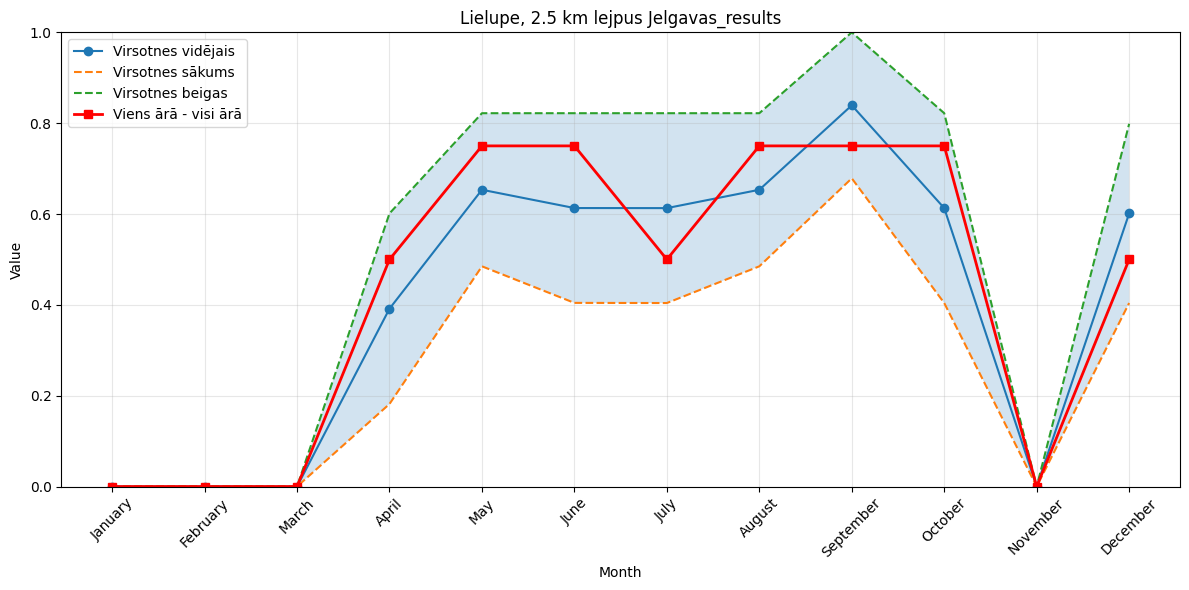

In [43]:
file_path = (
    r"full_analysis_results\Lielupe, 2.5 km lejpus Jelgavas"
    r"\Lielupe, 2.5 km lejpus Jelgavas_results.csv"
)

plot_data(file_path, "Lielupe, 2.5 km lejpus Jelgavas_results")
 

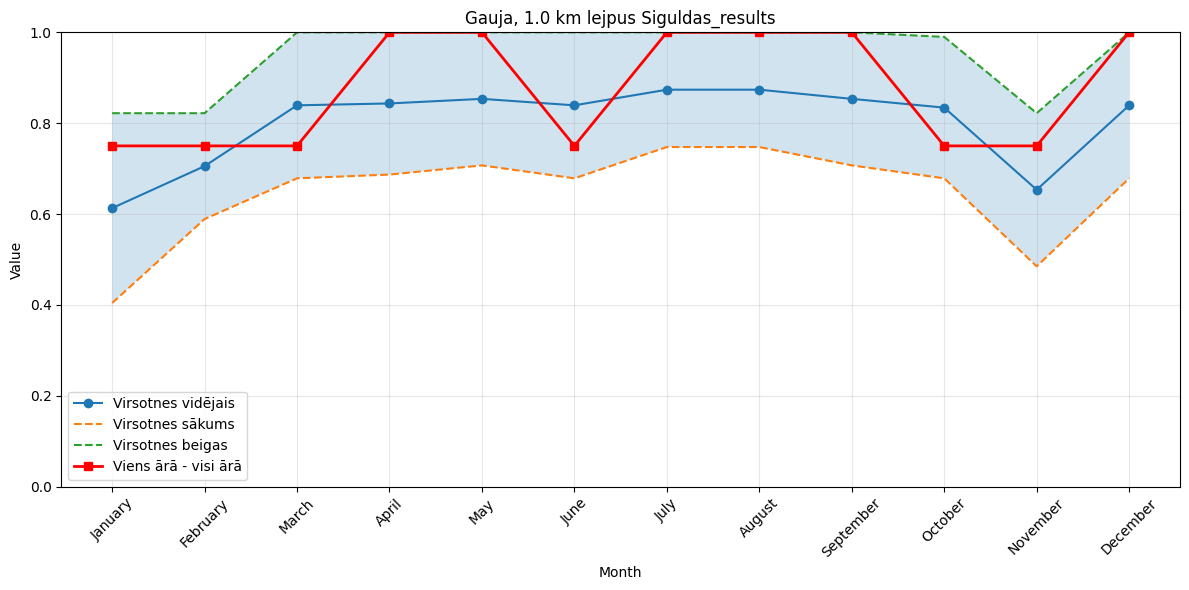

In [44]:
file_path = (
    r"full_analysis_results\Gauja, 1.0 km lejpus Siguldas"
    r"\Gauja, 1.0 km lejpus Siguldas_results.csv"
)

plot_data(file_path, "Gauja, 1.0 km lejpus Siguldas_results")

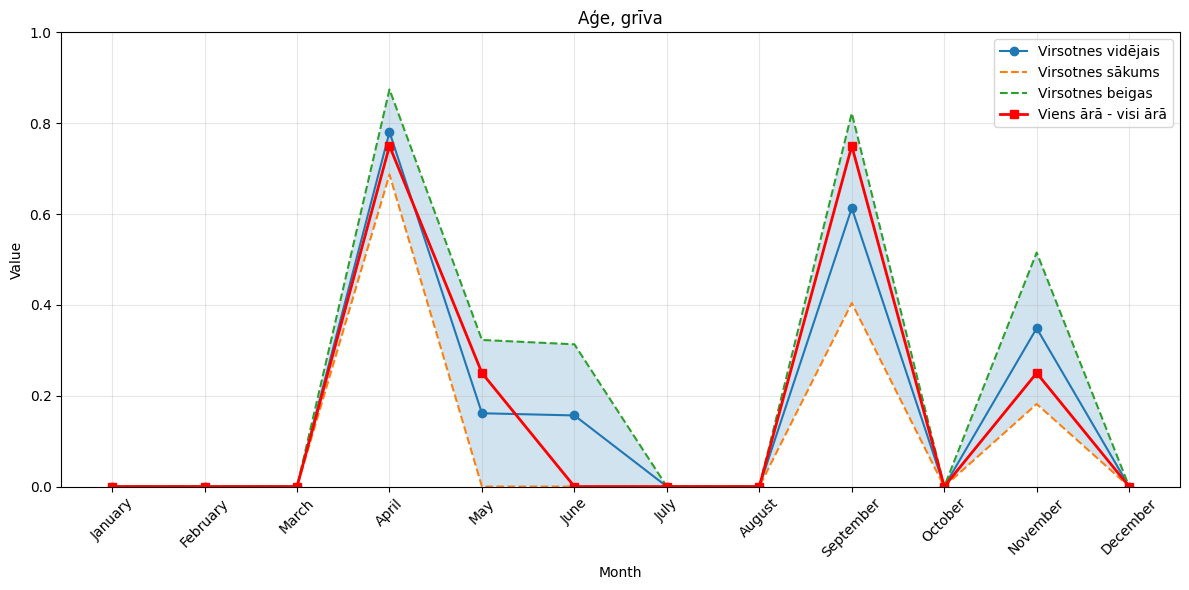

In [45]:
file_path = (
    r"full_analysis_results\A_e, gr_va"
    r"\A_e, gr_va_results.csv"
)

plot_data(file_path, "Aģe, grīva")